In [1]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

In [2]:
columns = [
    "age",
    "workclass",
    "fnlwgt",
    "education",
    "education-num",
    "marital-status",
    "occupation",
    "relationship",
    "race",
    "sex",
    "capital-gain",
    "capital-loss",
    "hours-per-week",
    "native-country",
    "income"
]

In [3]:
data = pd.read_csv(
    r"G:\Downloads\adult\adult.data",
    names = columns
)

In [4]:
data.head()

,age,workclass,fnlwgt,education,education-num,marital-status,occupation,relationship,race,sex,capital-gain,capital-loss,hours-per-week,native-country,income
0,39,State-gov,77516,Bachelors,13,Never-married,Adm-clerical,Not-in-family,White,Male,2174,0,40,United-States,<=50K
1,50,Self-emp-not-inc,83311,Bachelors,13,Married-civ-spouse,Exec-managerial,Husband,White,Male,0,0,13,United-States,<=50K
2,38,Private,215646,HS-grad,9,Divorced,Handlers-cleaners,Not-in-family,White,Male,0,0,40,United-States,<=50K
3,53,Private,234721,11th,7,Married-civ-spouse,Handlers-cleaners,Husband,Black,Male,0,0,40,United-States,<=50K
4,28,Private,338409,Bachelors,13,Married-civ-spouse,Prof-specialty,Wife,Black,Female,0,0,40,Cuba,<=50K


In [5]:
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 32561 entries, 0 to 32560
Data columns (total 15 columns):
 #   Column          Non-Null Count  Dtype 
---  ------          --------------  ----- 
 0   age             32561 non-null  int64 
 1   workclass       32561 non-null  object
 2   fnlwgt          32561 non-null  int64 
 3   education       32561 non-null  object
 4   education-num   32561 non-null  int64 
 5   marital-status  32561 non-null  object
 6   occupation      32561 non-null  object
 7   relationship    32561 non-null  object
 8   race            32561 non-null  object
 9   sex             32561 non-null  object
 10  capital-gain    32561 non-null  int64 
 11  capital-loss    32561 non-null  int64 
 12  hours-per-week  32561 non-null  int64 
 13  native-country  32561 non-null  object
 14  income          32561 non-null  object
dtypes: int64(6), object(9)
memory usage: 3.7+ MB


In [6]:
data.describe(include = 'all')

,age,workclass,fnlwgt,education,education-num,marital-status,occupation,relationship,race,sex,capital-gain,capital-loss,hours-per-week,native-country,income
count,32561.000000,32561,3.256100e+04,32561,32561.000000,32561,32561,32561,32561,32561,32561.000000,32561.000000,32561.000000,32561,32561
unique,NaN,9,NaN,16,NaN,7,15,6,5,2,NaN,NaN,NaN,42,2
top,NaN,Private,NaN,HS-grad,NaN,Married-civ-spouse,Prof-specialty,Husband,White,Male,NaN,NaN,NaN,United-States,<=50K
freq,NaN,22696,NaN,10501,NaN,14976,4140,13193,27816,21790,NaN,NaN,NaN,29170,24720
mean,38.581647,NaN,1.897784e+05,NaN,10.080679,NaN,NaN,NaN,NaN,NaN,1077.648844,87.303830,40.437456,NaN,NaN
std,13.640433,NaN,1.055500e+05,NaN,2.572720,NaN,NaN,NaN,NaN,NaN,7385.292085,402.960219,12.347429,NaN,NaN
min,17.000000,NaN,1.228500e+04,NaN,1.000000,NaN,NaN,NaN,NaN,NaN,0.000000,0.000000,1.000000,NaN,NaN
25%,28.000000,NaN,1.178270e+05,NaN,9.000000,NaN,NaN,NaN,NaN,NaN,0.000000,0.000000,40.000000,NaN,NaN
50%,37.000000,NaN,1.783560e+05,NaN,10.000000,NaN,NaN,NaN,NaN,NaN,0.000000,0.000000,40.000000,NaN,NaN
75%,48.000000,NaN,2.370510e+05,NaN,12.000000,NaN,NaN,NaN,NaN,NaN,0.000000,0.000000,45.000000,NaN,NaN


In [7]:
data.isnull().sum()

age               0
workclass         0
fnlwgt            0
education         0
education-num     0
marital-status    0
occupation        0
relationship      0
race              0
sex               0
capital-gain      0
capital-loss      0
hours-per-week    0
native-country    0
income            0
dtype: int64

In [8]:
data.shape

(32561, 15)

array([[<Axes: title={'center': 'age'}>,
        <Axes: title={'center': 'fnlwgt'}>],
       [<Axes: title={'center': 'education-num'}>,
        <Axes: title={'center': 'capital-gain'}>],
       [<Axes: title={'center': 'capital-loss'}>,
        <Axes: title={'center': 'hours-per-week'}>]], dtype=object)

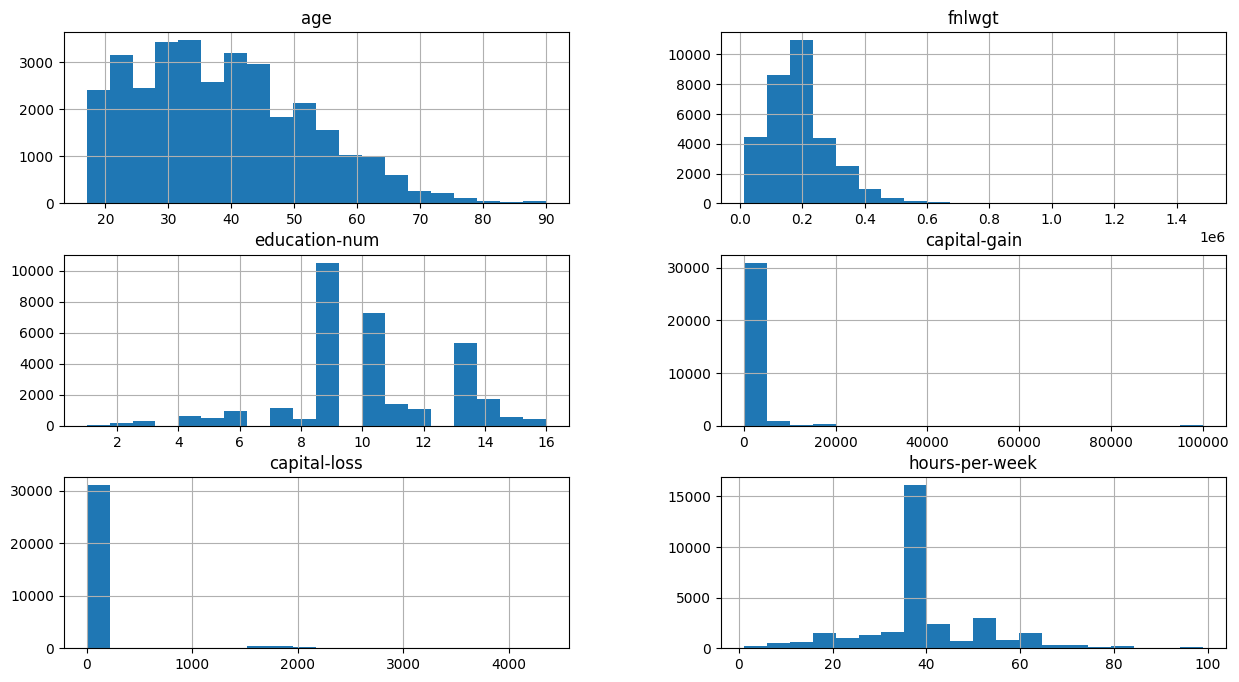

In [9]:
data.hist(figsize=(15,8), bins=20)


In [10]:
num_cols = data.select_dtypes(include=np.number).columns
num_df = data.select_dtypes(include=np.number)

<Axes: >

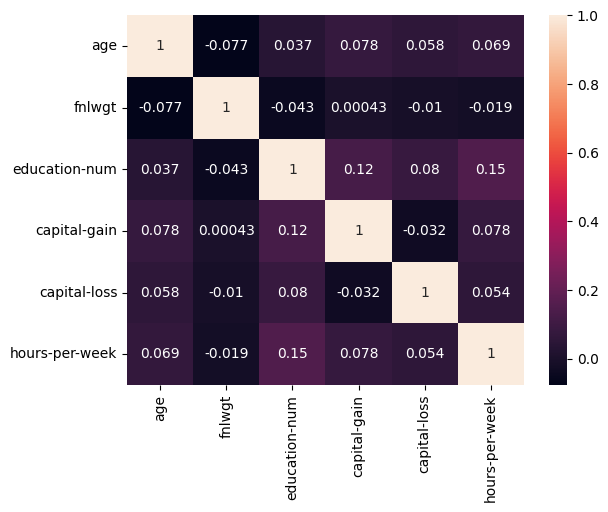

In [11]:
sns.heatmap(num_df.corr(), annot=True)

<Axes: xlabel='age', ylabel='count'>

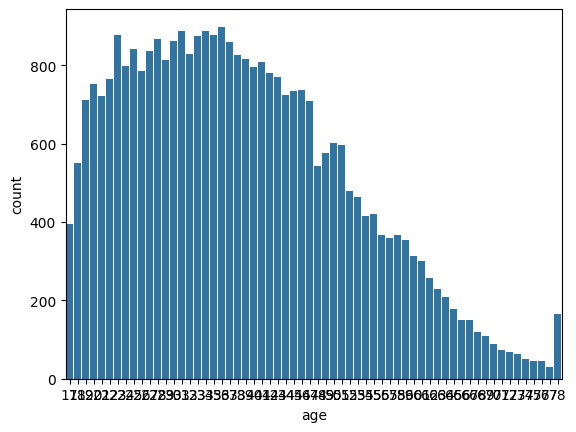

In [24]:
sns.countplot(x='age', data=data)

In [12]:
cat_cols = data.select_dtypes(include = ['object', 'string', 'category']).columns

In [13]:
print(cat_cols)
print(num_cols)

Index(['workclass', 'education', 'marital-status', 'occupation',
       'relationship', 'race', 'sex', 'native-country', 'income'],
      dtype='object')
Index(['age', 'fnlwgt', 'education-num', 'capital-gain', 'capital-loss',
       'hours-per-week'],
      dtype='object')


In [14]:
for cols in num_cols:
    data[cols] = data[cols].fillna(value='mean')

for cols in cat_cols:
    data[cols] = data[cols].fillna(value = 'mode'[0])

<Axes: >

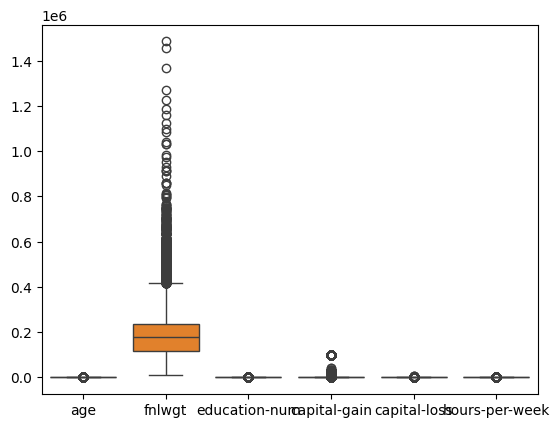

In [15]:
sns.boxplot(data=data.select_dtypes(include=np.number))

In [16]:
for cols in num_cols:
    Q1 = data[cols].quantile(0.25)
    Q3 = data[cols].quantile(0.75)

    IQR = Q3-Q1
    lower = Q1-1.5*IQR
    upper = Q3+1.5*IQR

    outlier = data[(data[cols]<lower) | (data[cols]>upper)]
    print(cols , len(outlier))

age 143
fnlwgt 992
education-num 1198
capital-gain 2712
capital-loss 1519
hours-per-week 9008


In [17]:
for cols in num_cols:
    Q1 = data[cols].quantile(0.25)
    Q3 = data[cols].quantile(0.75)

    IQR = Q3-Q1
    lower = Q1-1.5*IQR
    upper = Q3+1.5*IQR

    data[cols] = data[cols].clip(lower, upper)

<Axes: >

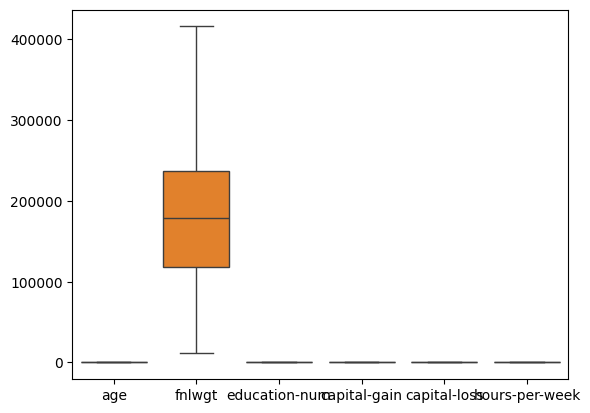

In [18]:
sns.boxplot(data=data.select_dtypes(include=np.number))

In [19]:
for cols in num_cols:
    Q1 = data[cols].quantile(0.25)
    Q3 = data[cols].quantile(0.75)

    IQR = Q3-Q1
    lower = Q1-1.5*IQR
    upper = Q3+1.5*IQR

    outlier = data[(data[cols]<lower) | (data[cols]>upper)]
    print(cols , len(outlier))

age 0
fnlwgt 0
education-num 0
capital-gain 0
capital-loss 0
hours-per-week 0


In [20]:
data_encoder = pd.get_dummies(data, drop_first = True)

In [21]:
data_encoder.head()

,age,fnlwgt,education-num,capital-gain,capital-loss,hours-per-week,workclass_ Federal-gov,workclass_ Local-gov,workclass_ Never-worked,workclass_ Private,...,native-country_ Puerto-Rico,native-country_ Scotland,native-country_ South,native-country_ Taiwan,native-country_ Thailand,native-country_ Trinadad&Tobago,native-country_ United-States,native-country_ Vietnam,native-country_ Yugoslavia,income_ >50K
0,39,77516,13.0,0,0,40.0,False,False,False,False,...,False,False,False,False,False,False,True,False,False,False
1,50,83311,13.0,0,0,32.5,False,False,False,False,...,False,False,False,False,False,False,True,False,False,False
2,38,215646,9.0,0,0,40.0,False,False,False,True,...,False,False,False,False,False,False,True,False,False,False
3,53,234721,7.0,0,0,40.0,False,False,False,True,...,False,False,False,False,False,False,True,False,False,False
4,28,338409,13.0,0,0,40.0,False,False,False,True,...,False,False,False,False,False,False,False,False,False,False


In [22]:
from sklearn.preprocessing import StandardScaler
scaler = StandardScaler()

data_encoded_scaled = scaler.fit_transform(data_encoder[num_cols])

In [23]:
scaled_df = pd.DataFrame(
    data_encoded_scaled,
    columns=num_cols,
    index=data.index
)

scaled_df.head()

,age,fnlwgt,education-num,capital-gain,capital-loss,hours-per-week
0,0.032782,-1.149114,1.169103,0.0,0.0,-0.194354
1,0.844236,-1.088196,1.169103,0.0,0.0,-1.406591
2,-0.040986,0.302927,-0.457091,0.0,0.0,-0.194354
3,1.065541,0.503446,-1.270187,0.0,0.0,-0.194354
4,-0.778671,1.593428,1.169103,0.0,0.0,-0.194354
